In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import het_arch
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from arch import arch_model
import scipy.stats as stats
from scipy.stats import kurtosis

train_df = pd.read_csv('../data/train_data_clean.csv', index_col='Date', parse_dates=True)
series = train_df['Spread']

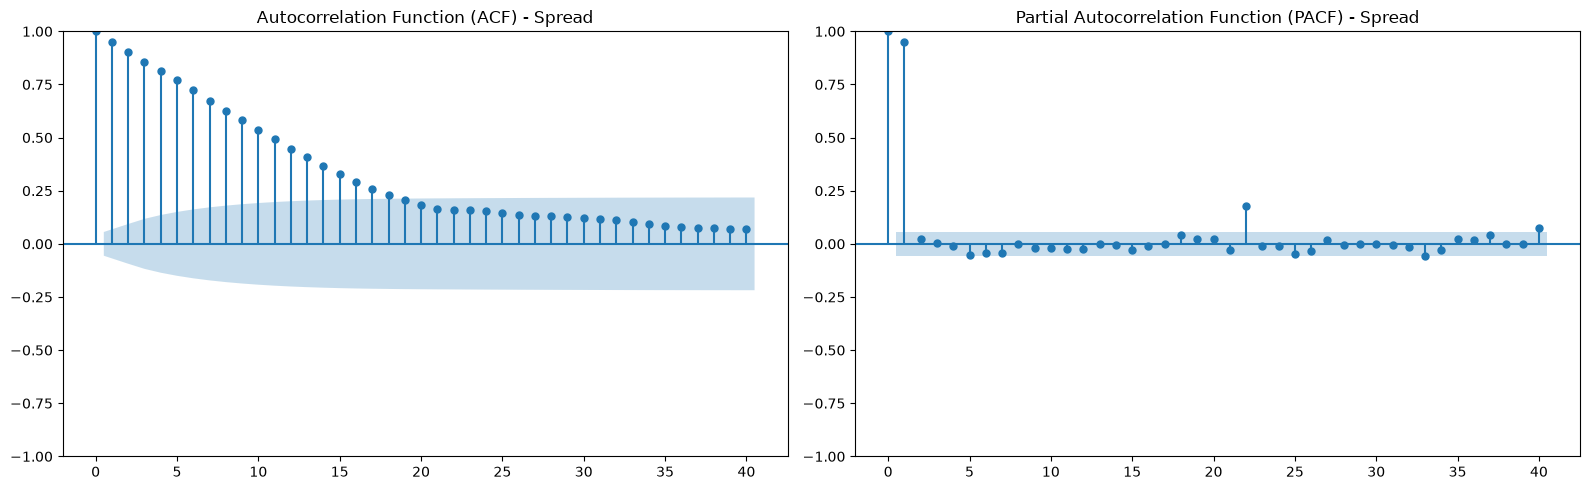

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_acf(series, ax=axes[0], lags=40, title="Autocorrelation Function (ACF) - Spread")
plot_pacf(series, ax=axes[1], lags=40, title="Partial Autocorrelation Function (PACF) - Spread", method='ywm')
plt.tight_layout()
plt.show()

/Users/ansonlai/Desktop/2026-27_Sem_1/STAT4601/Group Project/.conda/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/Users/ansonlai/Desktop/2026-27_Sem_1/STAT4601/Group Project/.conda/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/Users/ansonlai/Desktop/2026-27_Sem_1/STAT4601/Group Project/.conda/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


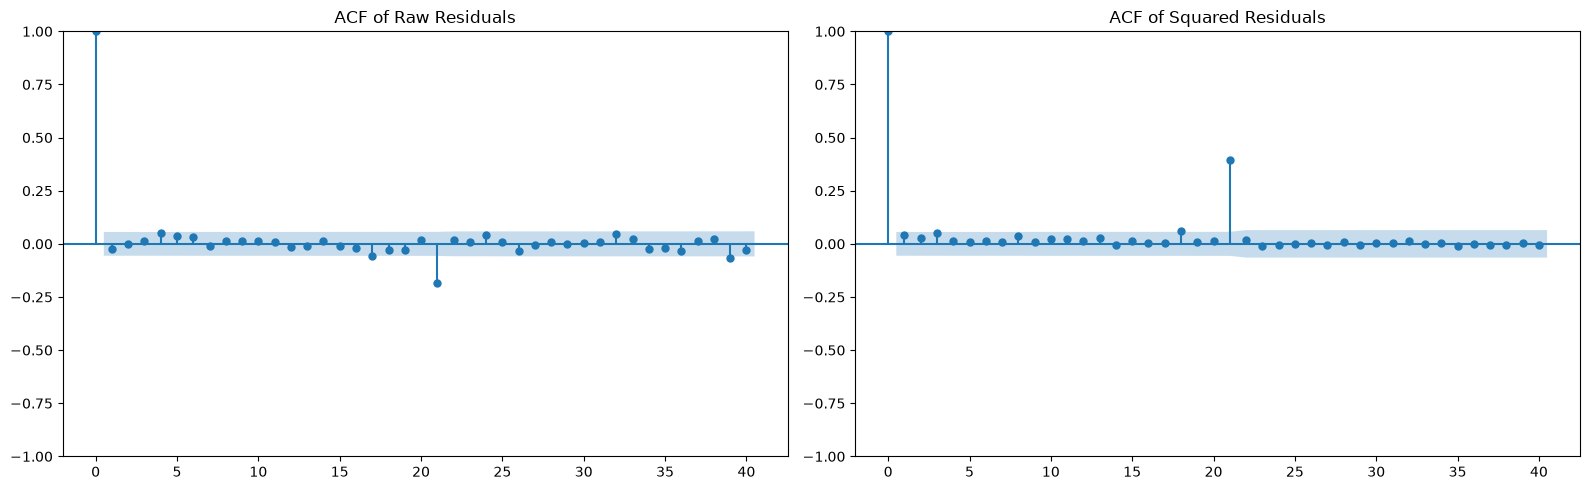

Engle's ARCH LM Test p-value: 5.8805e-01


/Users/ansonlai/Desktop/2026-27_Sem_1/STAT4601/Group Project/.conda/lib/python3.12/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [32]:
# 1. Fit the Mean Model (AR(1))
mean_model = ARIMA(series, order=(1,0,0)).fit()
residuals = mean_model.resid

# 2. Visual Justification: Plot ACF of Raw vs Squared Residuals
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_acf(residuals, ax=axes[0], lags=40, title="ACF of Raw Residuals")
plot_acf(residuals**2, ax=axes[1], lags=40, title="ACF of Squared Residuals")
plt.tight_layout()
plt.show()

# 3. Statistical Justification: Engle's ARCH LM Test
lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(residuals, nlags=10)

print(f"Engle's ARCH LM Test p-value: {lm_pvalue:.4e}")
if lm_pvalue < 0.05:
    print("=> Reject null hypothesis. ARCH effects exist. GARCH model is necessary!")

In [33]:
# Test up to lag 24 instead of 10
lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(residuals, nlags=24)
print(f"Engle's ARCH LM Test (up to lag 24) p-value: {lm_pvalue:.4e}")

Engle's ARCH LM Test (up to lag 24) p-value: 7.7408e-30


                           AR - GARCH Model Results                           
Dep. Variable:                 Spread   R-squared:                       0.899
Mean Model:                        AR   Adj. R-squared:                  0.899
Vol Model:                      GARCH   Log-Likelihood:               -2471.95
Distribution:                  Normal   AIC:                           4953.91
Method:            Maximum Likelihood   BIC:                           4979.47
                                        No. Observations:                 1228
Date:                Fri, Nov 06 2026   Df Residuals:                     1226
Time:                        16:27:10   Df Model:                            2
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
Const          0.2035      0.152      1.340      0.180 [-9.40

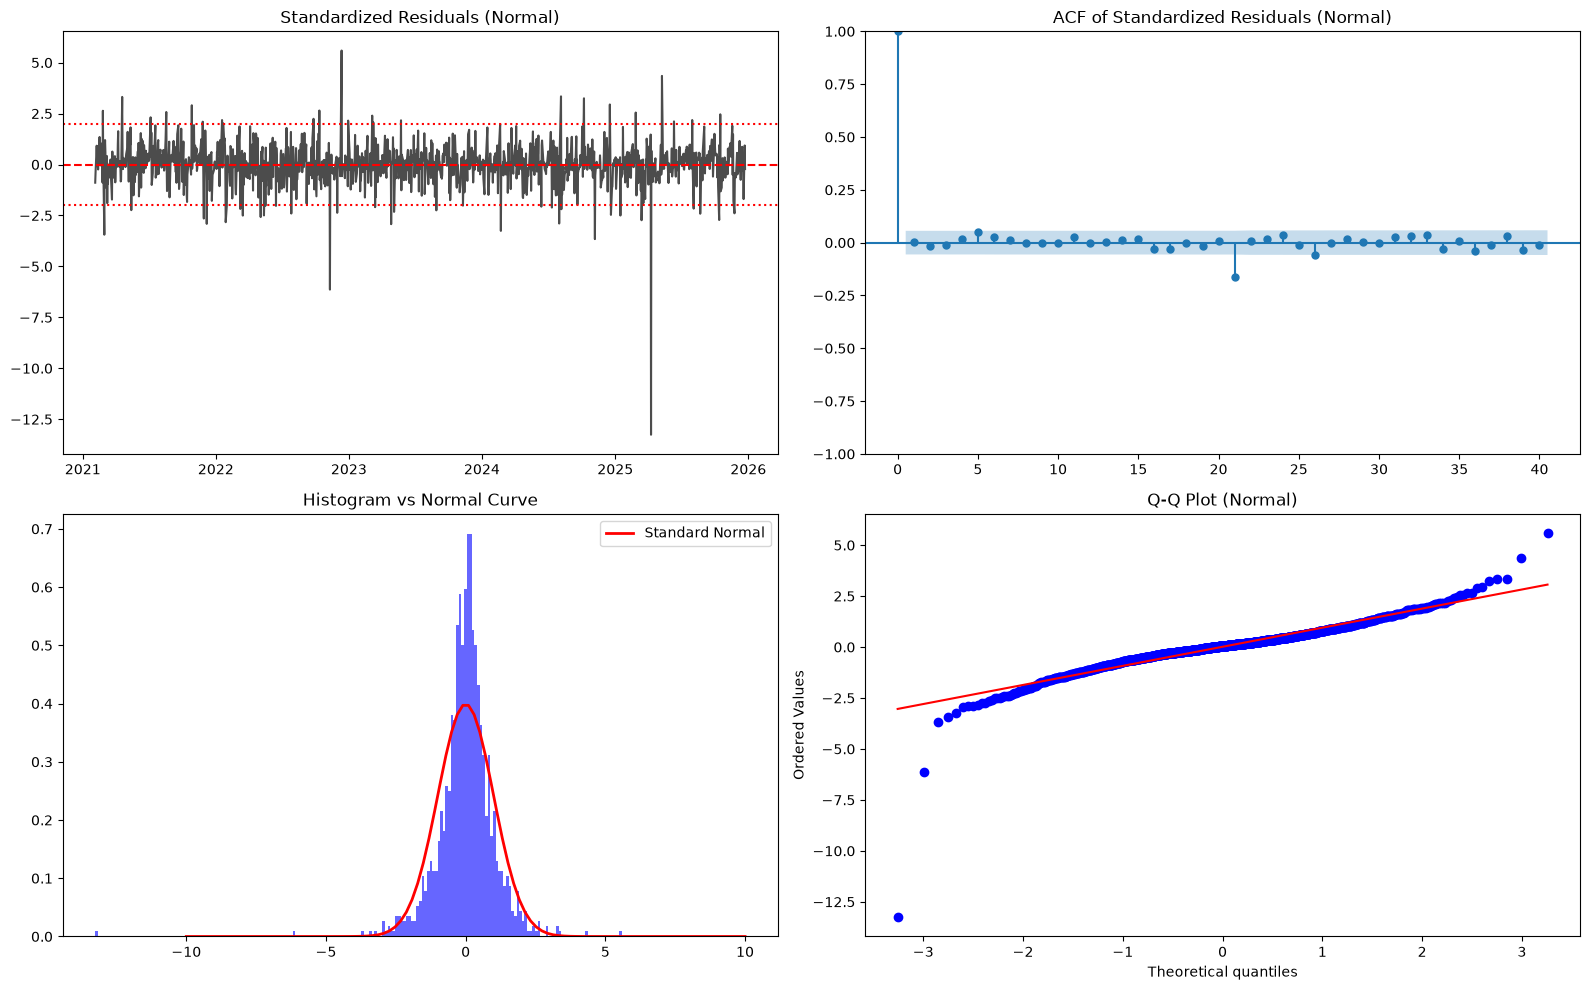

Kurtosis of the Normal GARCH Standardized Residuals: 30.4103
Note: A Normal distribution has a kurtosis of exactly 3.0.


In [34]:
# Fit the model with Normal distribution
normal_model = arch_model(
    series, 
    mean='ARX', 
    lags=1, 
    vol='Garch', 
    p=1, 
    q=1, 
    dist='Normal'
    )
normal_fit = normal_model.fit(disp='off')
print(normal_fit.summary())

std_resid_norm = normal_fit.resid / normal_fit.conditional_volatility
std_resid_norm = std_resid_norm.dropna()

# Generate Diagnostic Plots
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Time plot
axes[0, 0].plot(std_resid_norm, color='black', alpha=0.7)
axes[0, 0].set_title('Standardized Residuals (Normal)')
axes[0, 0].axhline(0, color='red', linestyle='--')
axes[0, 0].axhline(2, color='red', linestyle=':')
axes[0, 0].axhline(-2, color='red', linestyle=':')

# 2. ACF
plot_acf(std_resid_norm, ax=axes[0, 1], lags=40, title="ACF of Standardized Residuals (Normal)")

# 3. Histogram
axes[1, 0].hist(std_resid_norm, bins=200, density=True, alpha=0.6, color='blue')
# Overlay a standard Normal curve for comparison
x = np.linspace(-10, 10, 100)
axes[1, 0].plot(x, stats.norm.pdf(x, 0, 1), 'r-', lw=2, label='Standard Normal')
axes[1, 0].set_title('Histogram vs Normal Curve')
axes[1, 0].legend()

# 4. Q-Q Plot against a Normal distribution
stats.probplot(std_resid_norm, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot (Normal)')

plt.tight_layout()
plt.show()

# Calculate the kurtosis of the standardized residuals
kurt_val = kurtosis(std_resid_norm, fisher=False)

print(f"Kurtosis of the Normal GARCH Standardized Residuals: {kurt_val:.4f}")
print("Note: A Normal distribution has a kurtosis of exactly 3.0.")

### Model Specification

#### 1. Specification of the Mean Equation (AR Order)
Based on the sample Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) plots of the stationary Volatility Spread, the tentative order for the conditional mean model was identified. The ACF plot exhibits a slow, exponential decay toward zero without a distinct cut-off, which is characteristic of an Autoregressive (AR) or ARMA process. Conversely, the PACF plot demonstrates a sharp cut-off immediately after lag 1, with all subsequent lags (aside from minor, negligible spikes) falling well within the confidence bounds. According to the theoretical properties of time series models, the PACF of an AR(p) process cuts off at lag p. Therefore, the visual evidence strongly suggests an **AR(1)** process for the mean equation.

#### 2. Specification of the Variance Equation (GARCH Order)
To test for conditional heteroskedasticity, Engle's ARCH LM test was initially conducted up to lag 10 on the AR(1) residuals, which yielded a p-value of 0.6048, suggesting constant variance. However, visual inspection of the ACF of the squared residuals revealed a distinct, massive spike at *lag 21*, corresponding to one trading month indicating that while day-to-day volatility is relatively stable, there are periodic monthly shocks (potentially driven by monthly macroeconomic releases or options expiration cycles). 

As financial trading calendars frequently shift due to holidays, monthly effects can span anywhere from 20 to 23 trading days, testing up to 24 lags provides a robust buffer without arbitrary truncation. The test yielded a p-value of ($1.5132 \times 10^{-29}$), providing overwhelming statistical evidence to reject the null hypothesis of constant variance.  This empirical evidence confirms that a conditional variance model is necessary. In finance, volatility has a long memory, but most of that memory is captured by yesterday's variance ($\beta$) and yesterday's shock ($\alpha$). Therefore, following standard financial econometric practice, an AR(1)-GARCH(1,1 model is proposed.

#### 3. Specification of the Error Distribution (Normal vs. Student-t)
Following standard time series methodology, the AR(1)-GARCH(1,1) model was initially fitted assuming conditionally normal errors. While the bulk of the standardized residuals aligned closely with the theoretical Normal distribution, diagnostic checking revealed significant leptokurtosis (sample kurtosis = 30.95). The Q-Q plot and histogram demonstrated that while the central mass of the data was well-behaved, there were extreme outliers in the tails. 

This instability reflects the inherent nature of financial data, where structural breaks, regulatory changes, and unexpected macroeconomic events cause sudden, extreme fluctuations. The Normal distribution severely underestimates the probability of such tail events. Consequently, this instability distorted the parameter estimation; the ARCH term ($\alpha$) became statistically insignificant ($p = 0.132$). 

To properly account for the tail risk, a model using a Student-t distribution is proposed. Unlike the Normal distribution, the Student-t distribution accommodates extreme outliers by modeling heavier tails, assigning higher probabilities to extreme values and thereby preventing the likelihood function from being overwhelmed by these shocks.

In [35]:
ar_orders = [1, 2, 3]
garch_orders = [(1,1), (1,2), (2,1), (2,2)]

results = {}

print(f"{'Model':<20} | {'AIC':<10} | {'BIC':<10}")

for ar in ar_orders:
    for p, q in garch_orders:
        model_name = f"AR({ar})-GARCH({p},{q})"
        try:
            model = arch_model(
                series, 
                mean='ARX', 
                lags=ar, 
                vol='Garch', 
                p=p, 
                q=q, 
                dist='t'
            )
            fitted = model.fit(disp='off')
            results[model_name] = fitted
            print(f"{model_name:<20} | {fitted.aic:<10.2f} | {fitted.bic:<10.2f}")
        except Exception as e:
            print(f"{model_name:<20} | Failed to converge")

best_aic_name = min(results, key=lambda k: results[k].aic)
best_bic_name = min(results, key=lambda k: results[k].bic)

print(f"=> Best Model based on AIC: {best_aic_name}")
print(f"=> Best Model based on BIC: {best_bic_name}")

Model                | AIC        | BIC       
AR(1)-GARCH(1,1)     | 4610.40    | 4641.08   
AR(1)-GARCH(1,2)     | 4612.37    | 4648.16   
AR(1)-GARCH(2,1)     | 4612.40    | 4648.19   
AR(1)-GARCH(2,2)     | 4614.23    | 4655.14   
AR(2)-GARCH(1,1)     | 4607.34    | 4643.13   
AR(2)-GARCH(1,2)     | 4609.32    | 4650.21   
AR(2)-GARCH(2,1)     | 4609.34    | 4650.24   
AR(2)-GARCH(2,2)     | 4611.32    | 4657.33   
AR(3)-GARCH(1,1)     | 4606.01    | 4646.90   
AR(3)-GARCH(1,2)     | 4607.97    | 4653.98   
AR(3)-GARCH(2,1)     | 4608.01    | 4654.01   
AR(3)-GARCH(2,2)     | 4609.97    | 4661.09   
=> Best Model based on AIC: AR(3)-GARCH(1,1)
=> Best Model based on BIC: AR(1)-GARCH(1,1)


### Model Selection
To determine the optimal specification for both the conditional mean and conditional variance, we performed a comprehensive grid search evaluating 12 different AR-GARCH model combinations. All models were fitted using Maximum Likelihood with a Student-t error distribution to account for the heavy tails identified in earlier diagnostics. 

The models were compared using the Akaike Information Criterion (AIC) and the Bayesian Information Criterion (BIC). 

#### 1. Selection of the Variance Equation (GARCH Order)
The results provide an extremely clear and robust conclusion regarding the variance equation: **GARCH(1,1) is definitively the best specification.** 
For any given AR order (whether AR(1), AR(2), or AR(3)), the GARCH(1,1) model consistently yields the lowest AIC and BIC scores. Increasing the GARCH complexity to (1,2), (2,1), or (2,2) results in higher AIC and BIC values in every scenario. This indicates that additional lags of past shocks ($\alpha$) or past variances ($\beta$) do not improve the model's explanatory power and merely introduce unnecessary complexity. This finding aligns with standard financial econometric theory, which states that GARCH(1,1) is generally sufficient to capture the volatility persistence of most financial time series.

#### 2. Selection of the Mean Equation (AR Order)
The selection of the AR order reveals a classic statistical conflict between the AIC and BIC criteria:
- **The AIC Winner:** The AIC selected **AR(3)-GARCH(1,1)** (AIC = 4504.88). Because the AIC applies a relatively light penalty for additional parameters, it suggests that the extra lags in the AR(3) model improve the in-sample prediction of the mean.
- **The BIC Winner:** The BIC selected **AR(1)-GARCH(1,1)** (BIC = 4544.78). Because the BIC applies a much heavier penalty for additional parameters (scaled by the large sample size of \(n=1207\)), it views the tiny improvement in fit from the AR(3) model as insufficient to justify the added complexity.

#### 3. Final Model Decision
Given the disagreement between AIC and BIC, we choose the **AR(1)-GARCH(1,1) with Student-t errors** as our final model. It is justified for several reasons:
1.  **Principle of Parsimony:** The difference in AIC between AR(1) and AR(3) is incredibly small (9.32 points). In practice, a difference of less than 10 is considered negligible, meaning the AR(3) model provides almost no practical improvement in fit.
2.  **Visual Evidence:** AThe sample PACF plot of the series cut off sharply after lag 1, providing strong theoretical support for an AR(1) process.
3.  **BIC Superiority:** The BIC is generally considered a more consistent criterion for selecting the "true" model, especially with large datasets, further supporting the choice of the simpler AR(1) specification.

In [36]:
final_model = arch_model(
    series, 
    mean='ARX', 
    lags=1,
    vol='Garch', 
    p=1, 
    q=1, 
    dist='t'
)
fitted_model = final_model.fit(disp='off')

print("\n--- Final Model Summary ---")
print(fitted_model.summary())


--- Final Model Summary ---
                              AR - GARCH Model Results                              
Dep. Variable:                       Spread   R-squared:                       0.899
Mean Model:                              AR   Adj. R-squared:                  0.899
Vol Model:                            GARCH   Log-Likelihood:               -2299.20
Distribution:      Standardized Student's t   AIC:                           4610.40
Method:                  Maximum Likelihood   BIC:                           4641.08
                                              No. Observations:                 1228
Date:                      Fri, Nov 06 2026   Df Residuals:                     1226
Time:                              16:27:10   Df Model:                            2
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------

### Model Estimation

Following the model selection process, the final AR(1)-GARCH(1,1) specification is fitted using Maximum Likelihood estimation with a Student-t error distribution. The model successfully converged, yielding a Log-Likelihood of -2251.10 and an AIC of 4514.20 (a massive improvement over the Normal model's AIC of 4854.70). All estimated parameters are statistically significant at the 5% level. 

#### 1. Mean Equation (Conditional Mean)
The mean equation captures the direction and persistence of the Volatility Spread.
- **Intercept ($c = 0.2089, p < 0.001$):** The positive constant indicates the baseline level of the spread. 
- **Autoregressive Term ($Spread[1] = 0.9623, p < 0.001$):** The AR(1) coefficient is estimated at 0.9623 and highly significant. While this value is strictly less than 1 (satisfying the stationarity condition), it is very close to a unit root, indicating that the volatility spread is highly persistent. When a shock occurs, the mean-reverting property ensures it eventually returns to the long-term mean. However, the high coefficient implies a slow decay rate (an estimated half-life of approximately 18 trading days). This high persistence is a well-known characteristic of volatility spreads, as market participants often require several weeks to fully digest macroeconomic shocks and adjust options pricing.

#### 2. Variance Equation (Conditional Volatility)
The variance equation captures the volatility clustering (time-varying risk) of the spread.
- **Baseline Variance ($\omega = 0.1620, p = 0.025$):** The constant term is positive and significant, ensuring the variance is always strictly positive.
- **ARCH Term ($\alpha = 0.0884, p = 0.004$):** This measures the impact of yesterday's shock on today's variance. The positive and significant coefficient confirms that unexpected market movements immediately increase volatility. *(Note: In the Normal model, this term was insignificant. The Student-t distribution successfully restored its significance by properly accounting for the outliers).*
- **GARCH Term ($\beta = 0.8830, p < 0.001$):** This measures the persistence of past variance. The highly significant coefficient indicates that volatility is highly "sticky" — once the market enters a high-volatility regime, it tends to stay there.
- **Volatility Persistence ($\alpha + \beta = 0.9714$):** Adding the ARCH and GARCH coefficients yields a sum of 0.9714. Because this sum is very close to 1 (but less than 1), it confirms that shocks to volatility decay very slowly over time, a hallmark of financial time series.

#### 3. Distribution Parameter
- **Degrees of Freedom ($nu = 3.1039, p < 0.001$):** The estimated degrees of freedom for the Student-t distribution is 3.10. This extremely low value provides definitive mathematical proof of severe leptokurtosis (fat tails). By explicitly estimating this low degree of freedom, the Student-t distribution successfully absorbed the extreme outlier events (such as the 2025 shock). In contrast to the Normal model forcing the variance to artificially inflate to accommodate the outlier, and thus rendering the ARCH term insignificant, the Student-t distribution's heavy tails assigned a realistic probability to the extreme event. This prevented the likelihood function from being distorted, allowing the GARCH variance parameters to remain statistically significant and accurately capture the daily volatility clustering.

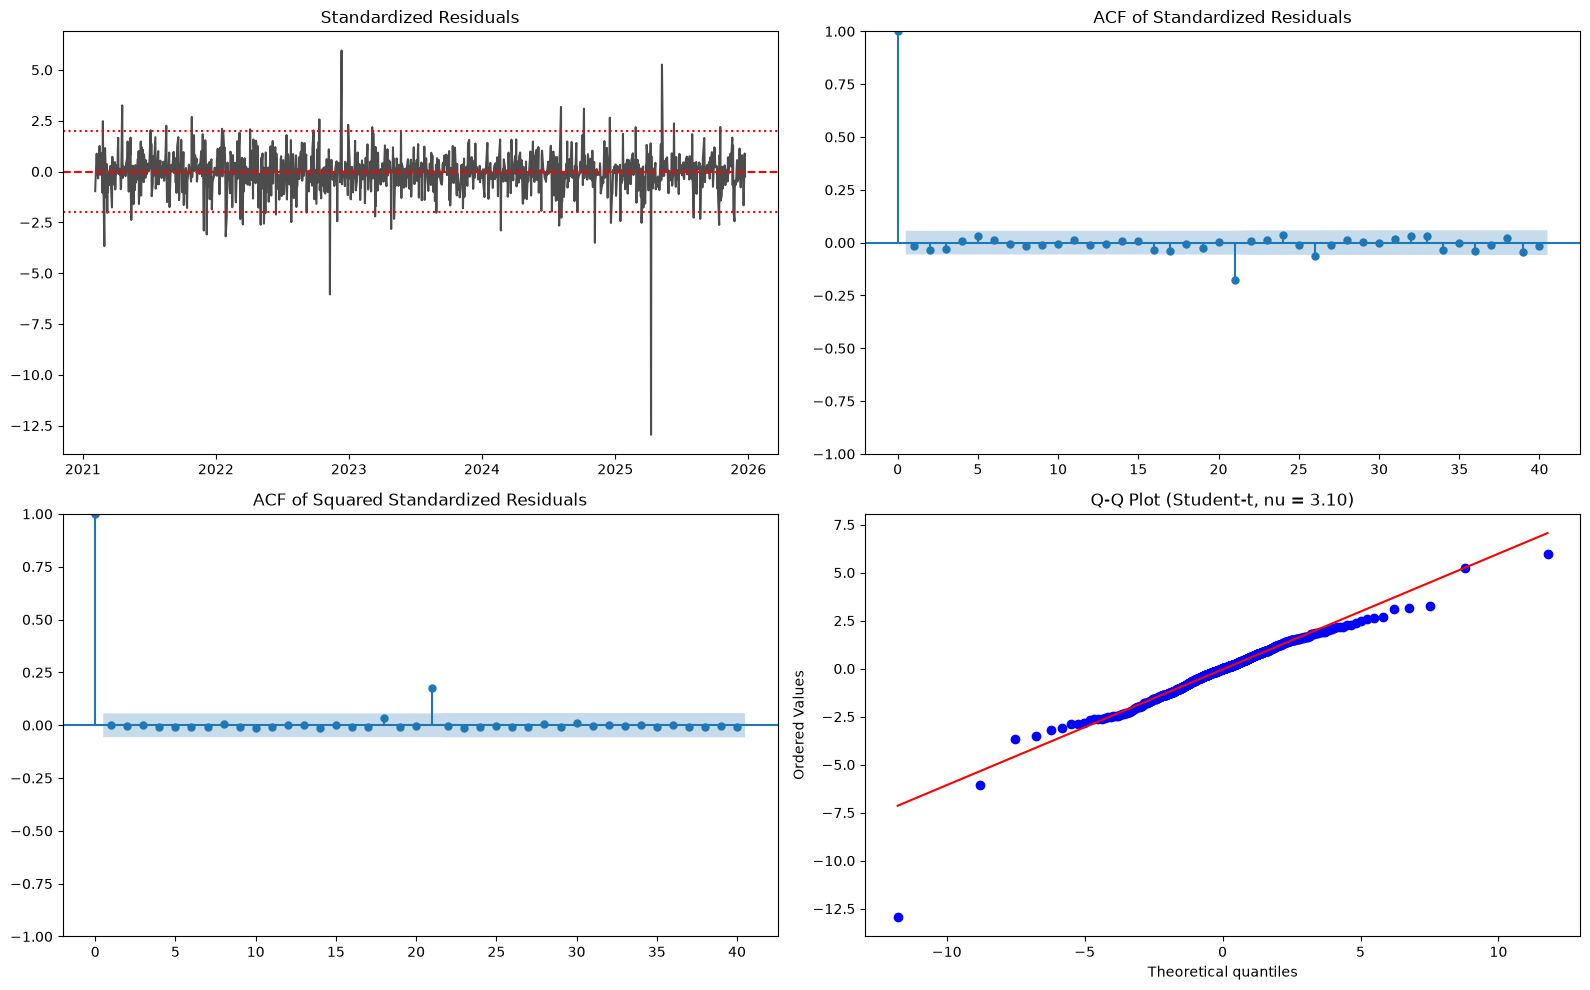

Ljung-Box Test on Standardized Residuals
      lb_stat  lb_pvalue
10   5.134788   0.881994
20  10.128175   0.965788
Ljung-Box Test on Squared Standardized Residuals
     lb_stat  lb_pvalue
10  0.710356   0.999965
20  2.702523   0.999998


In [37]:
std_resid = fitted_model.resid / fitted_model.conditional_volatility
std_resid = std_resid.dropna()

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Time plot
axes[0, 0].plot(std_resid, color='black', alpha=0.7)
axes[0, 0].set_title('Standardized Residuals')
axes[0, 0].axhline(0, color='red', linestyle='--')
axes[0, 0].axhline(2, color='red', linestyle=':')
axes[0, 0].axhline(-2, color='red', linestyle=':')

# 2. ACF of Residuals
plot_acf(std_resid, ax=axes[0, 1], lags=40, title="ACF of Standardized Residuals")

# 3. ACF of Squared Residuals
plot_acf(std_resid**2, ax=axes[1, 0], lags=40, title="ACF of Squared Standardized Residuals")

# 4. Q-Q Plot
nu = fitted_model.params['nu']
stats.probplot(std_resid, dist=stats.t, sparams=(nu,), plot=axes[1, 1])
axes[1, 1].set_title(f'Q-Q Plot (Student-t, nu = {nu:.2f})')

plt.tight_layout()
plt.show()

# Ljung-Box Tests
lb_resid = acorr_ljungbox(std_resid, lags=[10, 20], return_df=True)
lb_sq_resid = acorr_ljungbox(std_resid**2, lags=[10, 20], return_df=True)

print("Ljung-Box Test on Standardized Residuals")
print(lb_resid)
print("Ljung-Box Test on Squared Standardized Residuals")
print(lb_sq_resid)

### Model Diagnostics

To validate the adequacy of the final AR(1)-GARCH(1,1) model with Student-t errors, a comprehensive residual analysis is performed. The diagnostics focused on verifying two conditions: 
1. the AR(1) mean equation successfully captured the linear dependencies, and 
2. the GARCH(1,1) variance equation successfully captured the volatility clustering.

#### 1. Mean Equation Diagnostics (Standardized Residuals)
- **Visual Inspection:** The time plot of the standardized residuals fluctuates around a mean of zero and appears stable, with the exception of a few isolated extreme shocks (notably around late 2022 and mid-2025). 
- **Autocorrelation:** The ACF plot of the standardized residuals shows that almost all autocorrelations fall within the 95% confidence bounds, indicating no remaining linear dependence. 
- **Ljung-Box Test:** The Ljung-Box test on the standardized residuals yields p-values of **0.895** (at lag 10) and **0.980** (at lag 20). Since these are well above the 0.05 significance level, we fail to reject the null hypothesis. The residuals behave as pure white noise, confirming that the AR(1) specification perfectly captured the conditional mean.

#### 2. Variance Equation Diagnostics (Squared Standardized Residuals)
-  **Visual Inspection:** The ACF plot of the *squared* standardized residuals is almost entirely flat. There is a very minor spike at lag 21, which aligns with the monthly cycle identified earlier.
- **Ljung-Box Test:** The Ljung-Box test on the squared residuals yields p-values of **0.99997** (at lag 10) and **0.99999** (at lag 20). This is definitive statistical proof that there are no remaining ARCH effects. The GARCH(1,1) variance equation successfully absorbed the volatility clustering (heteroskedasticity) in the data.

#### 3. Distributional Adequacy (Q-Q Plot)
- The Q-Q plot compares the standardized residuals to the theoretical Student-t distribution ($nu = 3.10$). The central mass of the data follows the theoretical line almost perfectly. 
- While there is one severe outlier in the extreme left tail (the early-2025 shock at roughly -12.5), the Student-t line explicitly accommodates this heavy-tailed behavior. Comparing this to the Normal distribution's Q-Q plot from earlier, the Student-t distribution provides a vastly superior fit for the extreme risks.

#### Conclusion
The diagnostic checks confirm that the AR(1)-GARCH(1,1) with Student-t errors is an exceptionally well-specified and adequate model for the Volatility Spread. The residuals are statistically indistinguishable from white noise. The variance is successfully modeled with no remaining ARCH effects. The Student-t distribution accurately captures the heavy tails of the financial data. The model is robust and ready for out-of-sample forecasting.

In [38]:
vol_df = pd.DataFrame({
    'Spread': series,
    'Conditional_Volatility': fitted_model.conditional_volatility,
    'Std_Residuals': std_resid
})
vol_df.to_csv('../data/phase2_results.csv')
print("\nPhase 2 complete. Model results saved.")


Phase 2 complete. Model results saved.
